In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

# Orders data

In [13]:
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

orders = pd.read_excel("orders.xlsx")

orders = orders.loc[:, ~orders.columns.str.contains("^Unnamed")]

orders["date"] = pd.to_datetime(orders["date"])
orders["month"] = pd.to_datetime(orders["month"])

orders.head()

,month,code,count,lat,long,date,city,warehouse_zip
0,2017-06-01,13658,2,44.70,-75.30,2017-06-28,"Lisbon, St. Lawrence County",12189
1,2017-06-01,48456,2,43.70,-82.70,2017-06-28,"Minden City, Sanilac County",46168
2,2017-06-01,50323,2,41.64,-93.81,2017-06-28,"Urbandale, Dallas County",46168
3,2017-06-01,60614,2,41.92,-87.65,2017-06-28,"Chicago, Cook County",46168
4,2017-06-01,85395,2,33.48,-112.40,2017-06-28,"Goodyear, Maricopa County",91761


In [14]:
overview = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Date from",
        "Date to",
        "Unique dates",
        "Unique locations (code)",
        "Unique cities",
        "Unique warehouses",
        "Total quantity",
    ],
    "Value": [
        f"{len(orders):,}",
        len(orders.columns),
        orders["date"].min().strftime("%Y-%m-%d"),
        orders["date"].max().strftime("%Y-%m-%d"),
        orders["date"].nunique(),
        f"{orders['code'].nunique():,}",
        f"{orders['city'].nunique():,}",
        orders["warehouse_zip"].nunique(),
        f"{orders['count'].sum():,}",
    ]
})

display(
    overview.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left", "padding": "8px"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#040D17"),
            ("font-weight", "bold"),
            ("text-align", "left")
        ]}
    ])
)

Metric,Value
Number of rows,"89,934"
Number of columns,8
Date from,2017-06-28
Date to,2020-01-06
Unique dates,840
Unique locations (code),"18,241"
Unique cities,"13,339"
Unique warehouses,7
Total quantity,"146,680"


In [15]:
quality = pd.DataFrame({
    "Data Type": orders.dtypes.astype(str),
    "Missing Values": orders.isna().sum(),
    "Missing (%)": (orders.isna().mean() * 100).round(2),
    "Unique Values": orders.nunique()
})

display(quality.style
    .background_gradient(subset=["Missing (%)"], cmap="YlOrRd")
    .format({"Missing (%)": "{:.2f}%"}))

print(f"Duplicate rows: {orders.duplicated().sum():,}")
print(f"Negative quantities: {(orders['count'] < 0).sum():,}")
print(f"Zero quantities: {(orders['count'] == 0).sum():,}")

,Data Type,Missing Values,Missing (%),Unique Values
month,datetime64[us],0,0.00%,32
code,int64,0,0.00%,18241
count,int64,0,0.00%,9
lat,float64,845,0.94%,2284
long,float64,845,0.94%,3825
date,datetime64[us],0,0.00%,840
city,str,0,0.00%,13339
warehouse_zip,int64,0,0.00%,7


Duplicate rows: 0
Negative quantities: 0
Zero quantities: 0


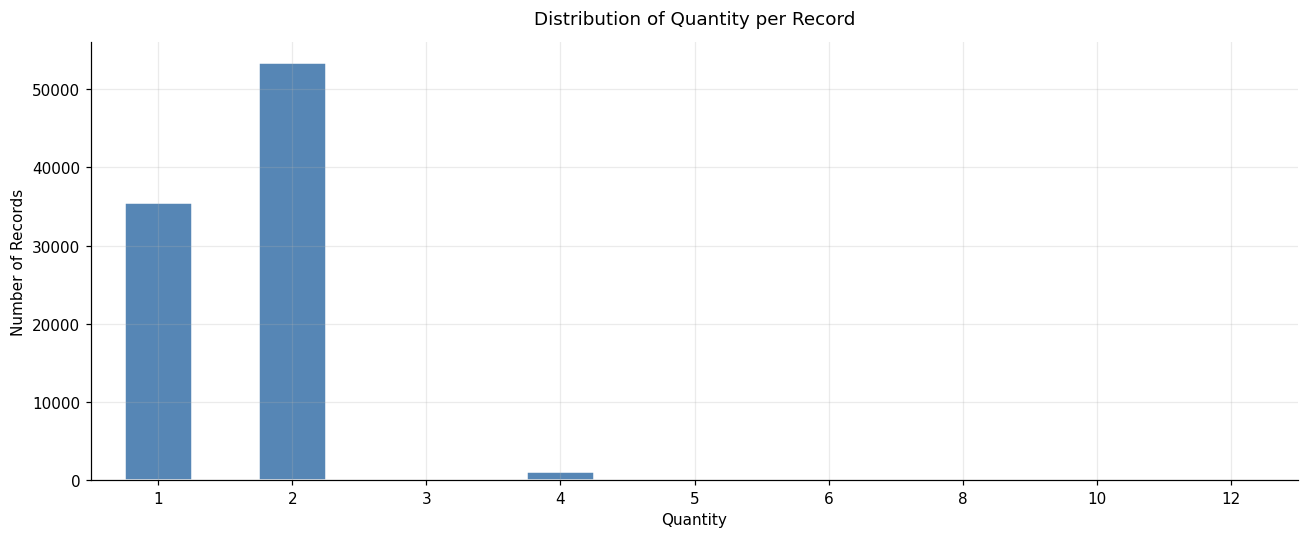

In [16]:
orders["count"].value_counts().sort_index().plot(
    kind="bar",
    color="#5686B5",
    edgecolor="white"
)

plt.title("Distribution of Quantity per Record", pad=12)
plt.xlabel("Quantity")
plt.ylabel("Number of Records")
plt.tick_params(axis="x", rotation=0)


plt.tight_layout()
plt.show()

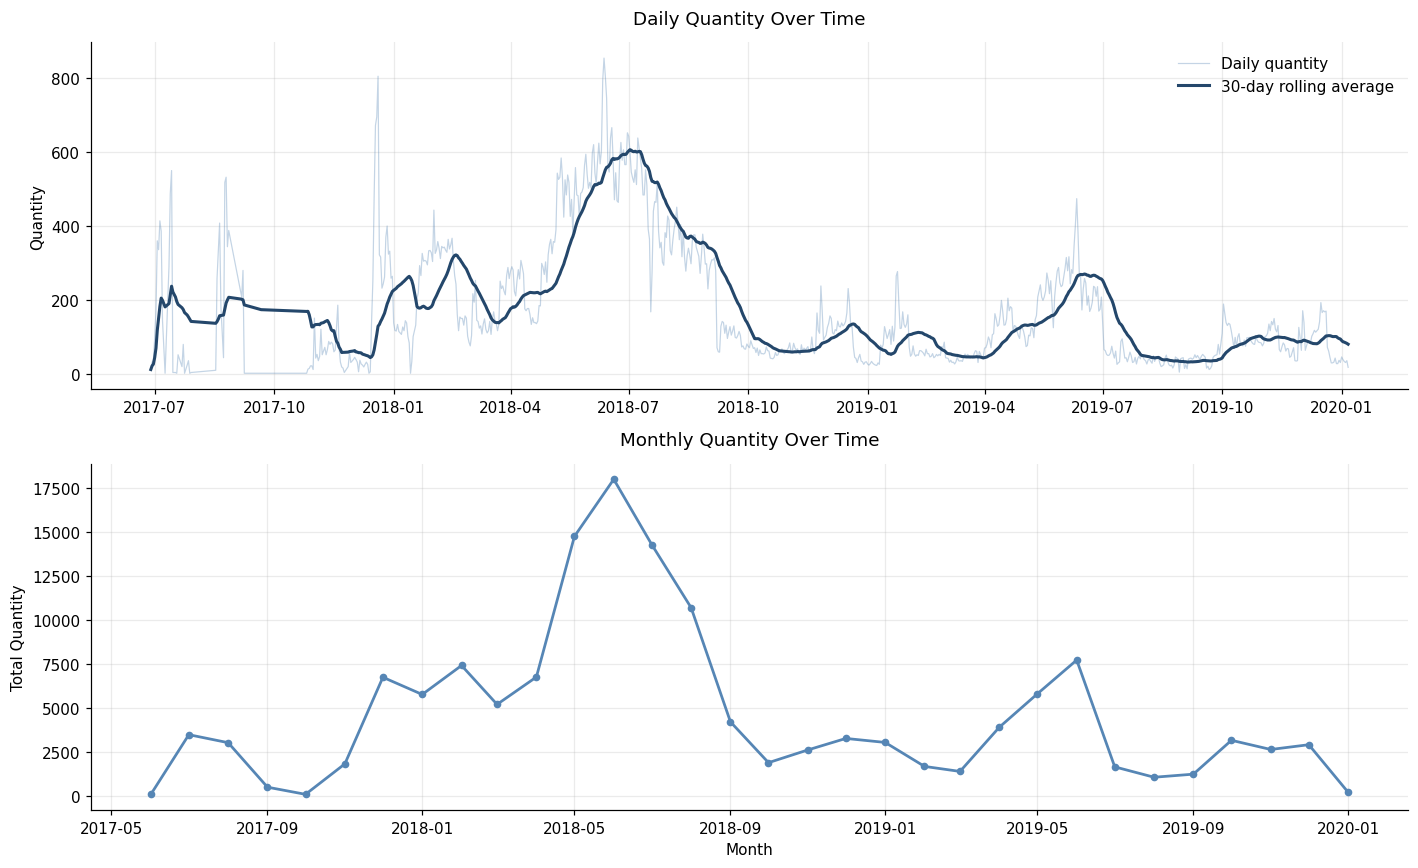

In [17]:
daily = (
    orders.groupby("date")["count"]
    .sum()
    .sort_index()
)

monthly = (
    orders.groupby("month")["count"]
    .sum()
    .sort_index()
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(
    daily.index,
    daily.values,
    color="#5686B5",
    alpha=0.35,
    linewidth=0.8,
    label="Daily quantity"
)

axes[0].plot(
    daily.index,
    daily.rolling(30, min_periods=1).mean(),
    color="#24476B",
    linewidth=2,
    label="30-day rolling average"
)

axes[0].set_title("Daily Quantity Over Time", pad=12)
axes[0].set_ylabel("Quantity")
axes[0].legend(frameon=False)

axes[1].plot(
    monthly.index,
    monthly.values,
    marker="o",
    markersize=4,
    linewidth=1.8,
    color="#5686B5"
)

axes[1].set_title("Monthly Quantity Over Time", pad=12)
axes[1].set_ylabel("Total Quantity")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()

Виражена сезонність: пік у травні – серпні, максимум у червні 2018 (~18 тис.). Пік 2019 року (~7,7 тис.) приблизно на 57% нижчий, тобто попит або продажі помітно просіли рік до року. Також є одноразовий спайк у грудні 2017 (~800/день)

,records,total_quantity,unique_locations
warehouse_zip,,,
17202,"25,338","40,811","4,898"
46168,"20,489","33,318","5,567"
75236,"13,256","21,922","2,767"
89434,"11,894","19,614","1,639"
91761,"11,869","18,975","1,306"
12189,"5,750","9,471","1,681"
99999,"1,338","2,569",383


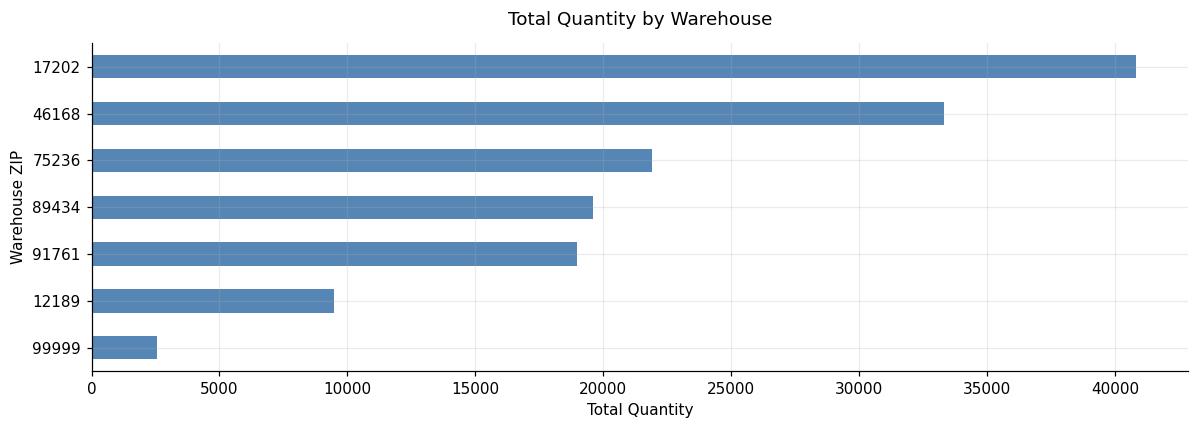

In [18]:
warehouse_stats = (
    orders.groupby("warehouse_zip")
    .agg(
        records=("count", "size"),
        total_quantity=("count", "sum"),
        unique_locations=("code", "nunique")
    )
    .sort_values("total_quantity", ascending=False)
)

display(
    warehouse_stats.style
    .format("{:,.0f}")
    .background_gradient(subset=["total_quantity"], cmap="Blues")
)

fig, ax = plt.subplots(figsize=(11, 4))

warehouse_stats["total_quantity"].sort_values().plot(
    kind="barh",
    ax=ax,
    color="#5686B5"
)

ax.set_title("Total Quantity by Warehouse", pad=12)
ax.set_xlabel("Total Quantity")
ax.set_ylabel("Warehouse ZIP")

plt.tight_layout()
plt.show()

In [19]:
print("ORDERS DATASET — KEY STATISTICS")
print("-" * 45)

print(f"Total records: {len(orders):,}")
print(f"Total quantity: {orders['count'].sum():,}")
print(f"Average quantity per record: {orders['count'].mean():.2f}")
print(f"Median quantity per record: {orders['count'].median():.0f}")
print(f"Maximum quantity per record: {orders['count'].max():,}")

print("\nTEMPORAL COVERAGE")
print("-" * 45)

print(f"Start date: {orders['date'].min().date()}")
print(f"End date: {orders['date'].max().date()}")
print(f"Number of unique dates: {orders['date'].nunique():,}")

print("\nGEOGRAPHIC COVERAGE")
print("-" * 45)

print(f"Unique locations: {orders['code'].nunique():,}")
print(f"Unique cities: {orders['city'].nunique():,}")
print(f"Unique warehouses: {orders['warehouse_zip'].nunique():,}")

print("\nDATA QUALITY")
print("-" * 45)

print(f"Missing values: {orders.isna().sum().sum():,}")
print(f"Duplicate rows: {orders.duplicated().sum():,}")

ORDERS DATASET — KEY STATISTICS
---------------------------------------------
Total records: 89,934
Total quantity: 146,680
Average quantity per record: 1.63
Median quantity per record: 2
Maximum quantity per record: 12

TEMPORAL COVERAGE
---------------------------------------------
Start date: 2017-06-28
End date: 2020-01-06
Number of unique dates: 840

GEOGRAPHIC COVERAGE
---------------------------------------------
Unique locations: 18,241
Unique cities: 13,339
Unique warehouses: 7

DATA QUALITY
---------------------------------------------
Missing values: 1,690
Duplicate rows: 0


# Sales data

In [20]:
sales = pd.read_excel("sales.xlsx")

sales["date"] = pd.to_datetime(sales["Unnamed: 0"])
sales = sales.drop(columns=["Unnamed: 0"])

sales = sales.sort_values("date").reset_index(drop=True)

sales.head()

,inventory_fbm,inventory_fba,automatic ice maker,ice maker under counter machine,ice maker 30,ice cube maker,ice maker,ice cube trays,ice maker machine,ice machine,...,counter ice machine,clear ice machine,ice machine portable,16 oz,best ice machine,ice makers,small ice machine,ice machine countertop,target,date
0,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-27
1,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-28
2,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-29
3,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-30
4,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-10-01


In [21]:
overview = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Date from",
        "Date to",
        "Unique dates",
        "Missing target values",
        "Zero target values",
        "Total target (non-missing)",
        "Number of search query features",
    ],
    "Value": [
        f"{len(sales):,}",
        len(sales.columns),
        sales["date"].min().strftime("%Y-%m-%d"),
        sales["date"].max().strftime("%Y-%m-%d"),
        sales["date"].nunique(),
        f"{sales['target'].isna().sum():,}",
        f"{(sales['target'] == 0).sum():,}",
        f"{sales['target'].sum():,.0f}",
        len([c for c in sales.columns if c not in [
            "date", "target", "inventory_fbm", "inventory_fba"
        ]])
    ]
})

display(
    overview.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left", "padding": "8px"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#121315"),
            ("font-weight", "bold"),
            ("text-align", "left")
        ]}
    ])
)

Metric,Value
Number of rows,"1,191"
Number of columns,54
Date from,2017-09-27
Date to,2020-12-30
Unique dates,1191
Missing target values,282
Zero target values,108
Total target (non-missing),"86,438"
Number of search query features,50


In [22]:
quality = pd.DataFrame({
    "Data Type": sales.dtypes.astype(str),
    "Missing Values": sales.isna().sum(),
    "Missing (%)": (sales.isna().mean() * 100).round(2),
    "Unique Values": sales.nunique()
})

display(
    quality.style
    .background_gradient(subset=["Missing (%)"], cmap="YlOrRd")
    .format({"Missing (%)": "{:.2f}%"})
)

print(f"Duplicate rows: {sales.duplicated().sum():,}")
print(f"Duplicate dates: {sales['date'].duplicated().sum():,}")

,Data Type,Missing Values,Missing (%),Unique Values
inventory_fbm,float64,0,0.00%,507
inventory_fba,float64,0,0.00%,475
automatic ice maker,float64,0,0.00%,56
ice maker under counter machine,float64,0,0.00%,24
ice maker 30,int64,0,0.00%,1
ice cube maker,float64,0,0.00%,50
ice maker,float64,0,0.00%,53
ice cube trays,float64,0,0.00%,91
ice maker machine,float64,0,0.00%,48
ice machine,float64,0,0.00%,34


Duplicate rows: 0
Duplicate dates: 0


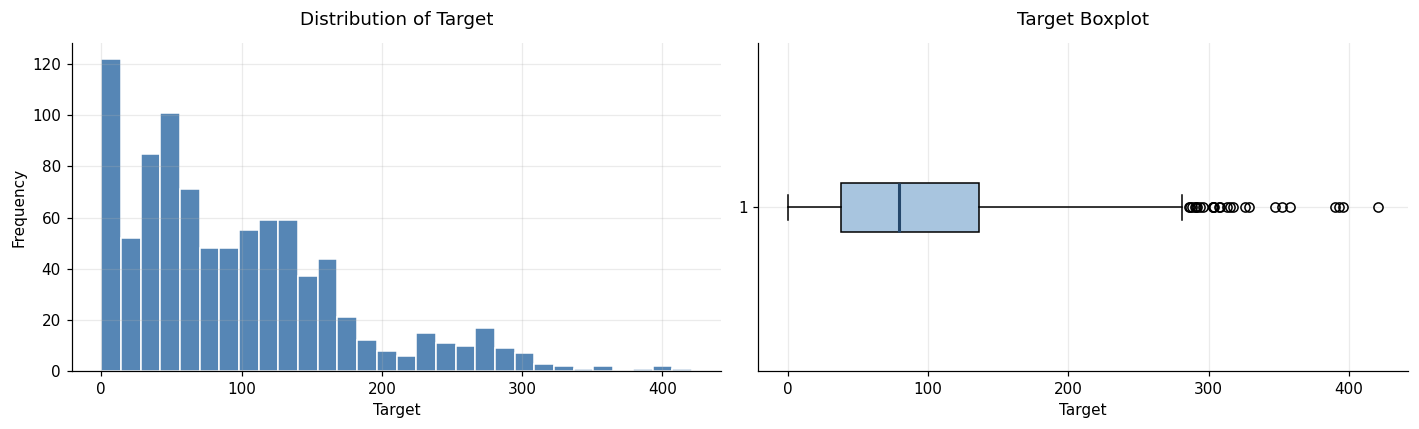

,Target Statistics
count,909.00
mean,95.09
std,78.52
min,0.00
25%,38.00
50%,79.00
75%,136.00
max,421.00


In [23]:
target = sales["target"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    target,
    bins=30,
    color="#5686B5",
    edgecolor="white"
)

axes[0].set_title("Distribution of Target", pad=12)
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(
    target,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#A8C5DF"),
    medianprops=dict(color="#24476B", linewidth=2)
)

axes[1].set_title("Target Boxplot", pad=12)
axes[1].set_xlabel("Target")

plt.tight_layout()
plt.show()

display(
    target.describe()
    .to_frame("Target Statistics")
    .round(2)
)

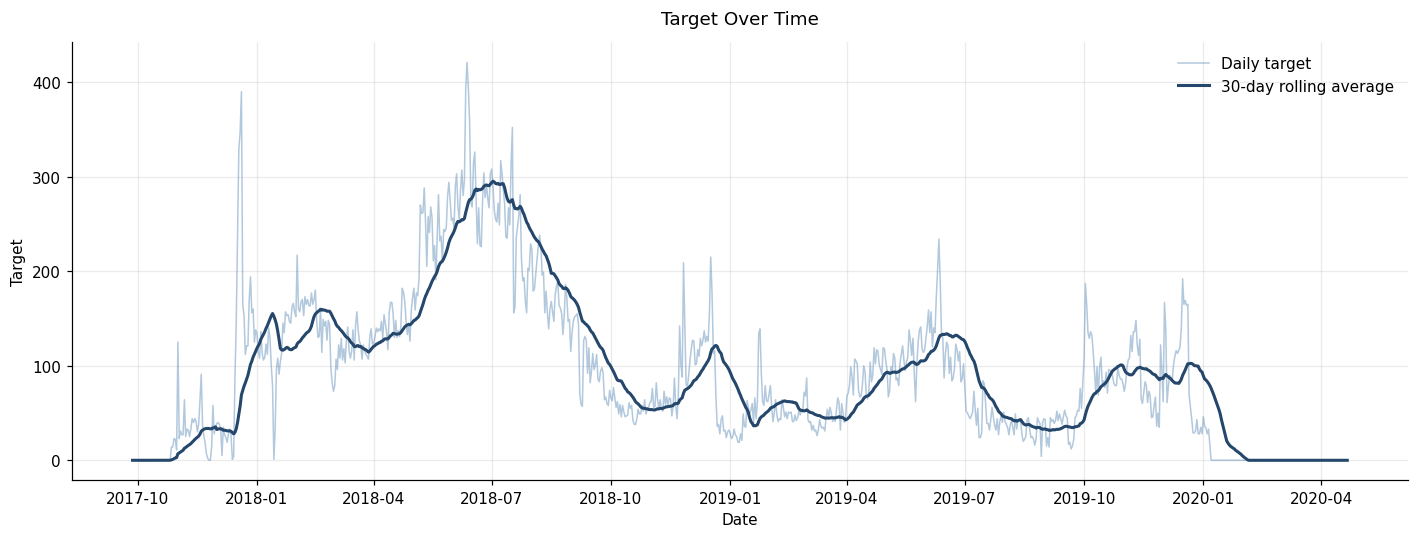

In [24]:
daily_target = (
    sales.set_index("date")["target"]
    .sort_index()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    daily_target.index,
    daily_target.values,
    color="#5686B5",
    alpha=0.45,
    linewidth=1,
    label="Daily target"
)

ax.plot(
    daily_target.index,
    daily_target.rolling(30, min_periods=1).mean(),
    color="#24476B",
    linewidth=2,
    label="30-day rolling average"
)

ax.set_title("Target Over Time", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Target")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

Динаміка майже повторює orders: пік у травні – липні 2018 (~300/день у згладженому ряді), менший пік влітку 2019 (~130) і невелике зростання у жовтні – грудні 2019. Присутня літня сезонність

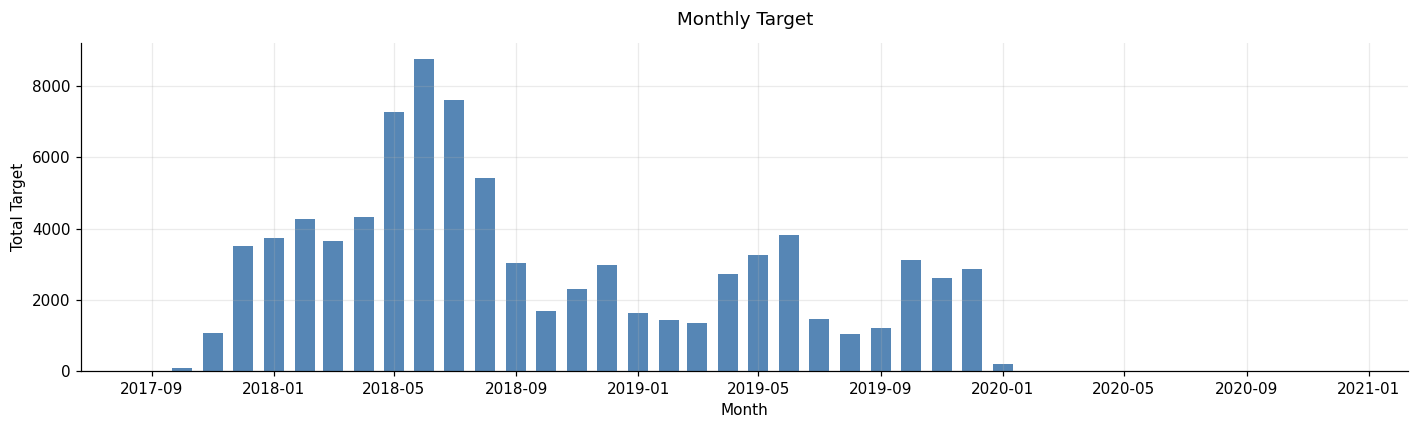

In [25]:
monthly_target = (
    sales.assign(month=sales["date"].dt.to_period("M"))
    .groupby("month")["target"]
    .agg(["sum", "mean", "count"])
)

monthly_target.index = monthly_target.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4))

ax.bar(
    monthly_target.index,
    monthly_target["sum"],
    width=20,
    color="#5686B5"
)

ax.set_title("Monthly Target", pad=12)
ax.set_xlabel("Month")
ax.set_ylabel("Total Target")

plt.tight_layout()
plt.show()

Максимум ~8,8 тис. у червні 2018, червень 2019 приблизно вдвічі-втричі нижчий (~3,8 тис.).

In [26]:
feature_cols = [
    c for c in sales.columns
    if c not in ["date", "target", "inventory_fbm", "inventory_fba"]
]

search_stats = sales[feature_cols].describe().T

search_stats = search_stats.sort_values(
    "mean",
    ascending=False
)

display(
    search_stats.head(15).round(2).style
    .background_gradient(subset=["mean"], cmap="Blues")
)

,count,mean,std,min,25%,50%,75%,max
under counter ice maker,1191.000000,4.600000,8.670000,0.000000,0.000000,0.000000,6.930000,46.000000
ice maker commercial,1191.000000,3.560000,5.600000,0.000000,0.000000,0.000000,10.650000,30.000000
ice cube trays,1191.000000,3.350000,5.790000,0.000000,0.000000,0.000000,6.000000,34.000000
ice maker under counter machine,1191.000000,3.010000,4.720000,0.000000,0.000000,0.000000,9.000000,32.000000
large ice machine,1191.000000,1.980000,4.800000,0.000000,0.000000,0.000000,0.000000,49.000000
clear ice maker,1191.000000,1.970000,3.360000,0.000000,0.000000,0.000000,5.900000,25.000000
crushed ice maker,1191.000000,1.580000,2.520000,0.000000,0.000000,0.000000,4.720000,16.000000
clear ice machine,1191.000000,1.470000,2.350000,0.000000,0.000000,0.000000,4.410000,19.000000
counter ice machine,1191.000000,1.140000,2.860000,0.000000,0.000000,0.000000,1.000000,27.000000
ice maker portable countertop,1191.000000,1.040000,3.120000,0.000000,0.000000,0.000000,1.000000,33.000000


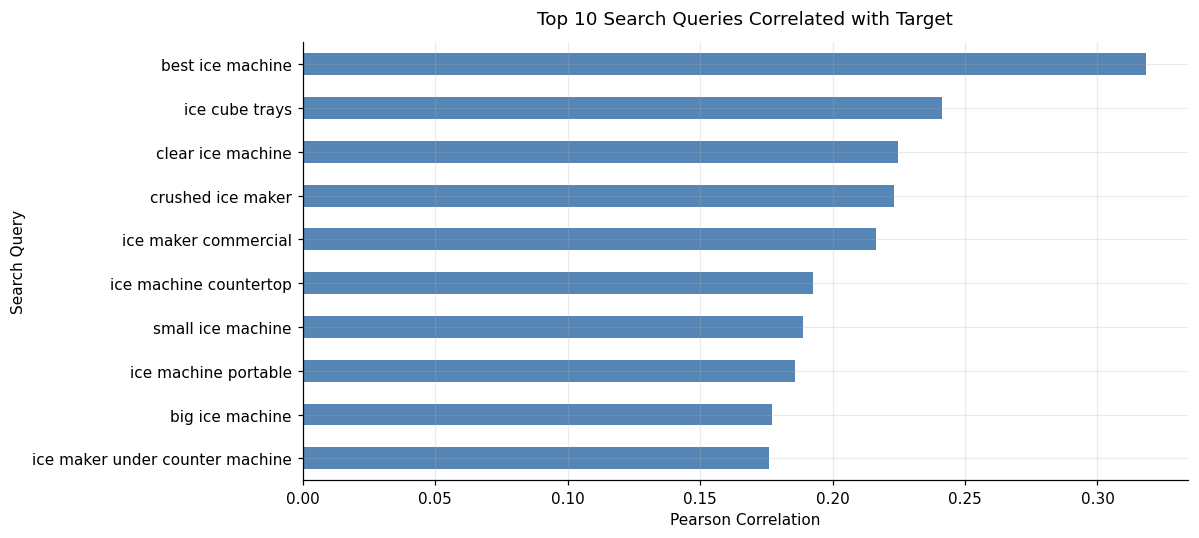

In [27]:
search_corr = (
    sales[["target"] + feature_cols]
    .corr()["target"]
    .drop("target")
    .dropna()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(11, 5))

search_corr.head(10).sort_values().plot(
    kind="barh",
    ax=ax,
    color="#5686B5"
)

ax.set_title("Top 10 Search Queries Correlated with Target", pad=12)
ax.set_xlabel("Pearson Correlation")
ax.set_ylabel("Search Query")

plt.tight_layout()
plt.show()

Кореляції слабкі або помірні (0,18–0,32), найвища у best ice machine (0,32).

In [29]:
print("SALES DATASET — KEY STATISTICS")
print("-" * 45)

print(f"Total records: {len(sales):,}")
print(f"Date range: {sales['date'].min().date()} — {sales['date'].max().date()}")
print(f"Unique dates: {sales['date'].nunique():,}")

print("\nTARGET VARIABLE")
print("-" * 45)

print(f"Available values: {sales['target'].notna().sum():,}")
print(f"Missing values: {sales['target'].isna().sum():,}")
print(f"Zero values: {(sales['target'] == 0).sum():,}")
print(f"Mean: {sales['target'].mean():.2f}")
print(f"Median: {sales['target'].median():.2f}")
print(f"Maximum: {sales['target'].max():.0f}")
print(f"Total: {sales['target'].sum():,.0f}")

print("\nINVENTORY")
print("-" * 45)

print(f"FBM mean: {sales['inventory_fbm'].mean():.2f}")
print(f"FBA mean: {sales['inventory_fba'].mean():.2f}")

print("\nSEARCH FEATURES")
print("-" * 45)

print(f"Number of search query features: {len(feature_cols)}")

print("\nDATA QUALITY")
print("-" * 45)

print(f"Duplicate rows: {sales.duplicated().sum():,}")
print(f"Duplicate dates: {sales['date'].duplicated().sum():,}")

SALES DATASET — KEY STATISTICS
---------------------------------------------
Total records: 1,191
Date range: 2017-09-27 — 2020-12-30
Unique dates: 1,191

TARGET VARIABLE
---------------------------------------------
Available values: 909
Missing values: 282
Zero values: 108
Mean: 95.09
Median: 79.00
Maximum: 421
Total: 86,438

INVENTORY
---------------------------------------------
FBM mean: 0.33
FBA mean: 0.29

SEARCH FEATURES
---------------------------------------------
Number of search query features: 50

DATA QUALITY
---------------------------------------------
Duplicate rows: 0
Duplicate dates: 0


# Competitors data

In [30]:
competitors = pd.read_excel("competitors.xlsx")

competitors = competitors.rename(
    columns={"Unnamed: 0": "date"}
)

competitors["date"] = pd.to_datetime(competitors["date"])

price_cols = [
    col for col in competitors.columns
    if col.endswith("_competitorPrice")
]

price_stats = competitors[price_cols].describe().T

display(price_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
B07GY4DS42_Igloo ICEB26AQ 26-Pound Automatic Portable Countertop Ice Maker Machine - Aqua 4.0 (220 reviews)_competitorPrice,204.0,133.54,7.64,107.30,127.22,139.99,139.99,143.49
"B004VV8GOQ_Frigidaire EFIC103 Ice Maker Machine Heavy Duty, Large Stainless Steel 3.3 (1575 reviews)_competitorPrice",204.0,128.79,12.70,106.66,116.70,133.05,141.68,152.99
"B07GVYF7Z5_Igloo ICEB26SS 26-Pound Automatic Portable Countertop Ice Maker Machine, Stainless Steel 4.0 (220 reviews)_competitorPrice",204.0,134.16,18.04,95.00,119.98,145.73,149.99,149.99
"B00INXG9MY_Compact Ice Maker, Red 3.7 (1958 reviews)_competitorPrice",204.0,106.53,11.56,81.91,98.25,106.05,115.69,139.99
"B01GE7V1H8_Frigidaire EFIC108-WHITE Portable Compact Maker, Counter Top Ice Making Machine, White 4.2 (109 reviews)_competitorPrice",204.0,134.42,36.28,76.05,97.18,119.99,170.66,170.66
"B074VG4CM8_Hamilton Beach PIM-1-3A Portable Ice Maker, 26 lb. Capacity, Black_competitorPrice",204.0,114.51,7.97,88.64,107.37,114.53,119.99,130.09
"B07GY5MBDJ_Igloo ICEB26BK Portable 26-Pound Automatic Ice Maker, Black 4.0 (220 reviews)_competitorPrice",204.0,124.01,18.32,82.87,108.99,139.99,139.99,139.99
"B07JBJWP2W_Frigidaire Counter Top Ice Maker, Produces 26 pounds Ice per Day, Stainless Steel with White See-through Lid 3.7 (30 reviews)_competitorPrice",204.0,134.84,34.44,79.31,99.00,133.51,169.44,190.81
"B074VG1DCZ_Hamilton Beach PIM-2-3A Portable Ice Maker, 26 lb. Capacity, Black Stainless Steel_competitorPrice",204.0,115.49,12.89,95.99,105.64,110.48,119.99,166.92


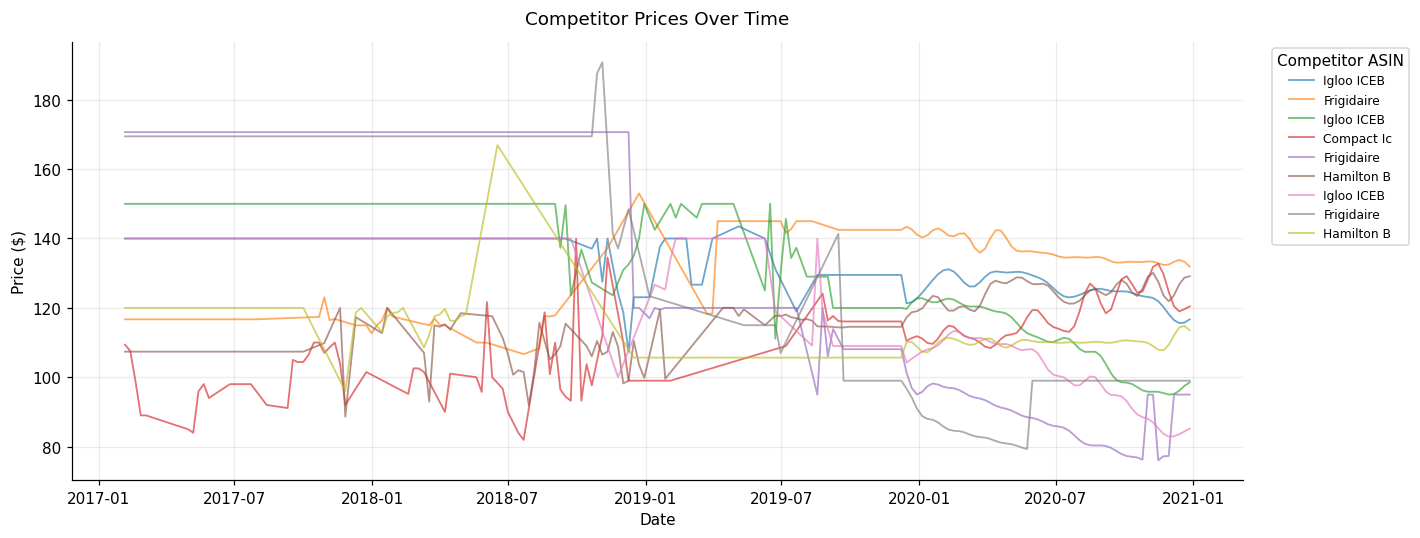

In [31]:
fig, ax = plt.subplots(figsize=(13, 5))

for col in price_cols:
    product_name = col.split("_")[1][:10]

    ax.plot(
        competitors["date"],
        competitors[col],
        alpha=0.65,
        linewidth=1.2,
        label=product_name
    )

ax.set_title("Competitor Prices Over Time", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Price ($)")
ax.legend(title="Competitor ASIN", bbox_to_anchor=(1.02, 1),
          loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

In [32]:
competitor_features = competitors[["date"]].copy()

prices = competitors[price_cols]

competitor_features["competitor_price_mean"] = prices.mean(axis=1)
competitor_features["competitor_price_median"] = prices.median(axis=1)
competitor_features["competitor_price_min"] = prices.min(axis=1)
competitor_features["competitor_price_max"] = prices.max(axis=1)
competitor_features["competitor_price_std"] = prices.std(axis=1)

display(competitor_features.head())

,date,competitor_price_mean,competitor_price_median,competitor_price_min,competitor_price_max,competitor_price_std
0,2017-02-05,135.943148,139.99,107.370,170.655,24.249568
1,2017-02-12,135.741296,139.99,107.370,170.655,24.504661
2,2017-02-19,134.764074,139.99,98.755,170.655,25.904800
3,2017-02-26,133.680185,139.99,89.000,170.655,27.738946
4,2017-03-05,133.680185,139.99,89.000,170.655,27.738946


In [33]:
competitors = pd.read_excel("competitors.xlsx")

competitors = competitors.rename(
    columns={"Unnamed: 0": "date"}
)

competitors["date"] = pd.to_datetime(competitors["date"])

ratio_cols = [
    col for col in competitors.columns
    if col.endswith("_competitorRatio")
]

inferred_prices = pd.DataFrame(index=competitors.index)

for ratio_col in ratio_cols:
    price_col = ratio_col.replace(
        "_competitorRatio",
        "_competitorPrice"
    )

    inferred_prices[ratio_col] = (
        competitors[price_col] / competitors[ratio_col]
    ).where(
        (competitors[price_col] > 0) &
        (competitors[ratio_col] > 0)
    )

# Aggregate inferred prices
competitors["our_price"] = inferred_prices.median(axis=1)

competitors["price_estimates_count"] = (
    inferred_prices.notna().sum(axis=1)
)

competitors["price_estimates_std"] = (
    inferred_prices.std(axis=1)
)

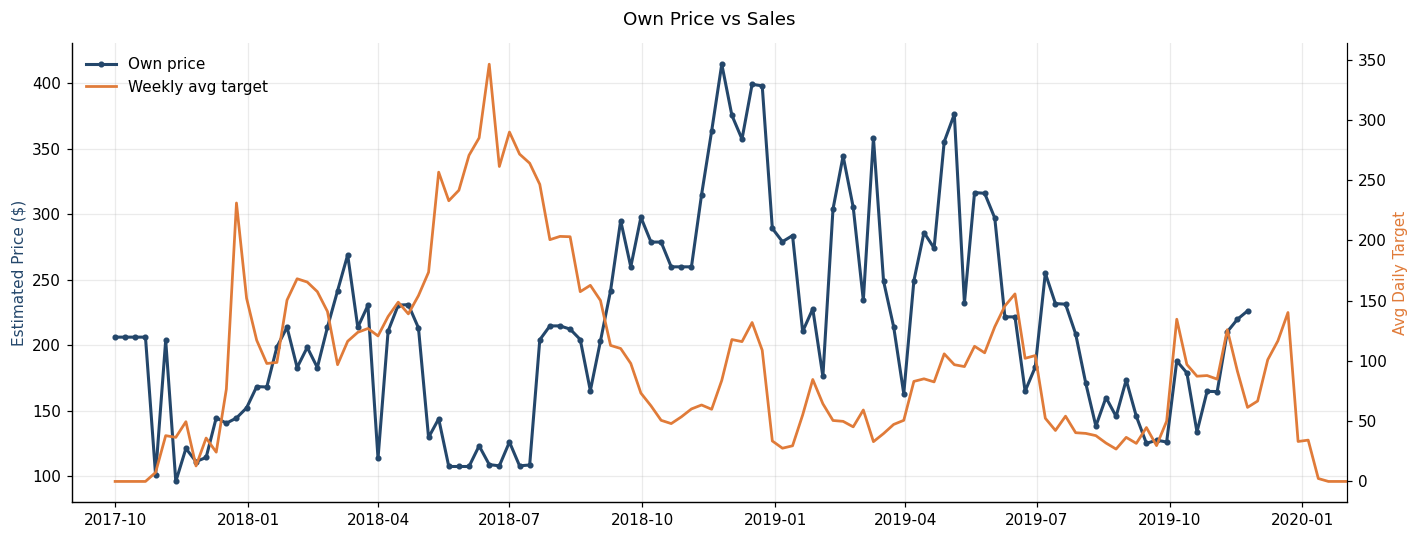

In [ ]:
weekly_target = (
    sales.set_index("date")["target"]
    .resample("W-SUN").mean()
)

price = competitors.set_index("date")["our_price"]

price = price.where(price.index < "2019-12-01")

fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(price.index, price.values, color="#24476B",
         linewidth=2, marker="o", markersize=3, label="Own price")
ax1.set_ylabel("Estimated Price ($)", color="#24476B")

ax2 = ax1.twinx()
ax2.plot(weekly_target.index, weekly_target.values, color="#E07B39",
         linewidth=1.8, label="Weekly avg target")
ax2.set_ylabel("Avg Daily Target", color="#E07B39")
ax2.spines["right"].set_visible(True)
ax2.grid(False)

ax1.set_xlim(pd.Timestamp("2017-09-01"), pd.Timestamp("2020-02-01"))
ax1.set_title("Own Price vs Sales", pad=12)

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

Власна ціна сильно коливається: 95–420$. Найнижча ~107$ у травні – липні 2018 збігається з піком продажів. Висока ~350–410$ у кінці 2018 і навесні 2019 супроводжується просіданням продажів, а зниження до 125–165$ у вересні – жовтні 2019 збігається із зростанням у жовтні 2019.

In [35]:
print("PRICE RECONSTRUCTION QUALITY")
print("-" * 40)

print(
    f"Available dates: "
    f"{competitors['our_price'].notna().sum()}"
)

print(
    f"Missing dates: "
    f"{competitors['our_price'].isna().sum()}"
)

print(
    f"Average number of competitor estimates: "
    f"{competitors['price_estimates_count'].mean():.2f}"
)

print(
    f"Mean disagreement between estimates: "
    f"${competitors['price_estimates_std'].mean():.4f}"
)

display(
    competitors["our_price"].describe().to_frame(
        "Reconstructed Price ($)"
    ).round(2)
)

PRICE RECONSTRUCTION QUALITY
----------------------------------------
Available dates: 170
Missing dates: 34
Average number of competitor estimates: 7.50
Mean disagreement between estimates: $0.0000


,Reconstructed Price ($)
count,170.00
mean,283.17
std,116.03
min,95.93
25%,184.35
50%,259.78
75%,422.78
max,422.78
